# 02 — Terrain and land-cover integration: pilot tile N22E070 (Gujarat)

**Project:** Data-driven wind-farm site suitability and turbine operational safety for India (classical ML)  
**Pipeline A, step 1** · previous: `01_niwe_data_cleaning_and_eda` · next: `03_india_terrain_landcover_integration`

This notebook developed and tested the method on a small area (Rajkot test DEM) and then on one complete 1° × 1° SRTM tile (N22E070, 61,992 NIWE points):

1. **SRTM 1″ terrain features** — mean elevation, slope (with geographic-distance correction) and local elevation standard deviation (ruggedness proxy) in a 17 × 17-pixel (~500 m) window;
2. **India-wide SRTM tile inventory** — 400 tiles needed for the 19.48 M NIWE points;
3. **Negative-elevation investigation** — 5,950 of 5,952 negative-elevation points lie on WorldCover *permanent water*, so they were kept and handled with land-cover information instead of being deleted;
4. **ESA WorldCover 2021** land-cover class at each point and a 500 m neighbourhood diagnostic on 415 points.

The method is scaled to all 400 tiles in notebook 03, which also replaces the per-point 500 m land-cover neighbourhood with an exact per-NIWE-cell calculation.

In [23]:
from google.colab import drive
import gdown
from pathlib import Path

# Install gdown if not already installed
try:
    import gdown
except ImportError:
    print("gdown not found. Installing gdown...")
    !pip install gdown --quiet
    import gdown

# Mount Google Drive to access files
drive.mount('/content/drive')

# Define Google Drive file ID from the provided URL
# URL: https://drive.google.com/file/d/1LUYOiRHeK81e6rmRLjg8GfZCTJHJ5SaD/view?usp=sharing
file_id = '1LUYOiRHeK81e6rmRLjg8GfZCTJHJ5SaD'

# Define paths for raw and processed data
RAW_FILE = Path("data/raw/150m_Map_Data_A_to_G.csv")
PROCESSED_DIR = Path("data/processed")

# Ensure the directories exist
RAW_FILE.parent.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Check if the raw file exists. If not, download it from Google Drive.
if not RAW_FILE.exists():
    print(f"Downloading {RAW_FILE.name} from Google Drive...")
    gdown.download(id=file_id, output=str(RAW_FILE), quiet=False)
    print(f"Downloaded {RAW_FILE.name} to {RAW_FILE}")
else:
    print(f"{RAW_FILE.name} already exists. Skipping download.")

print(f"Raw file path: {RAW_FILE}")
print(f"Raw file exists: {RAW_FILE.exists()}")
print(f"Processed data directory: {PROCESSED_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
150m_Map_Data_A_to_G.csv already exists. Skipping download.
Raw file path: data/raw/150m_Map_Data_A_to_G.csv
Raw file exists: True
Processed data directory: data/processed


In [24]:
!pip -q install elevation rasterio shapely geopandas

In [25]:
import os
import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt

from pathlib import Path

In [26]:
DATA_DIR = Path("data")
SRTM_DIR = DATA_DIR / "srtm"
TERRAIN_DIR = DATA_DIR / "terrain"

SRTM_DIR.mkdir(parents=True, exist_ok=True)
TERRAIN_DIR.mkdir(parents=True, exist_ok=True)

print("SRTM directory:", SRTM_DIR)
print("Terrain directory:", TERRAIN_DIR)

SRTM directory: data/srtm
Terrain directory: data/terrain


In [27]:
test_lat = 22.3039
test_lon = 70.8022

print("Latitude:", test_lat)
print("Longitude:", test_lon)

Latitude: 22.3039
Longitude: 70.8022


In [28]:
import elevation

test_dem = SRTM_DIR / "test_dem_inland.tif"

elevation.clip(
    bounds=(
        test_lon - 0.05,
        test_lat - 0.05,
        test_lon + 0.05,
        test_lat + 0.05
    ),
    output=str(test_dem)
)

print("DEM created:", test_dem.exists())
print("File:", test_dem)

DEM created: True
File: data/srtm/test_dem_inland.tif


In [29]:
import numpy as np
import rasterio

with rasterio.open(test_dem) as src:
    dem = src.read(1, masked=True)

    transform = src.transform
    crs = src.crs
    nodata = src.nodata
    bounds = src.bounds
    resolution = src.res

valid_elevation = dem.compressed()

print("CRS:", crs)
print("Resolution:", resolution)
print("Shape:", dem.shape)
print("NoData value:", nodata)
print("Masked pixels:", np.ma.getmaskarray(dem).sum())

if valid_elevation.size > 0:
    print("Minimum elevation:", valid_elevation.min())
    print("Maximum elevation:", valid_elevation.max())
    print("Mean elevation:", valid_elevation.mean())
else:
    print("No valid elevation pixels found.")

CRS: EPSG:4326
Resolution: (0.0002777777777777778, 0.0002777777777777778)
Shape: (360, 360)
NoData value: -32768.0
Masked pixels: 0
Minimum elevation: 96
Maximum elevation: 178
Mean elevation: 132.54796296296297


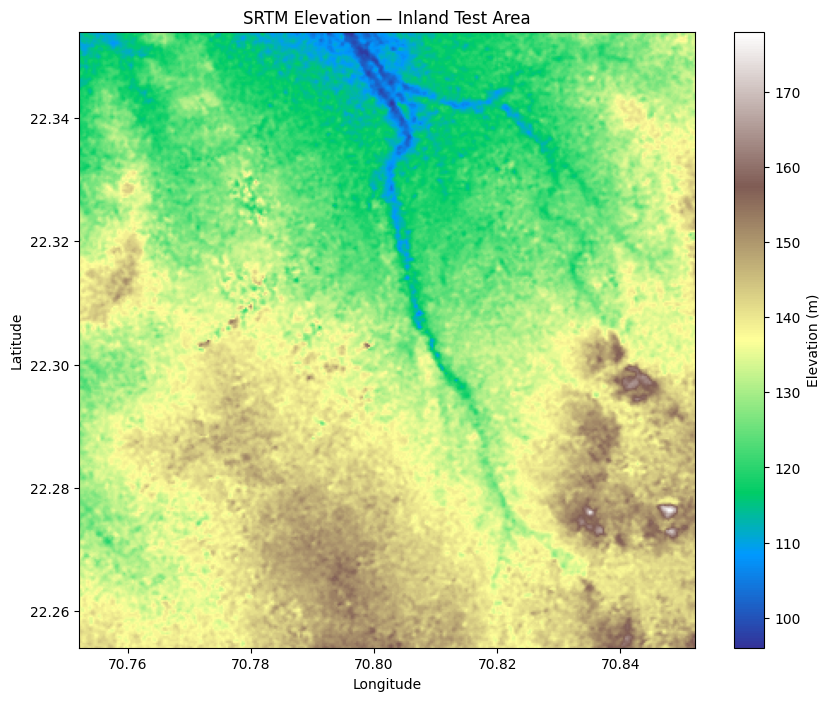

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.imshow(
    dem,
    extent=[
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ],
    origin="upper",
    cmap="terrain"
)

plt.colorbar(label="Elevation (m)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("SRTM Elevation — Inland Test Area")

plt.show()

In [31]:
from rasterio.transform import xy

pixel_x = abs(transform.a)
pixel_y = abs(transform.e)

print("Longitude pixel size:", pixel_x)
print("Latitude pixel size :", pixel_y)

Longitude pixel size: 0.0002777777777777778
Latitude pixel size : 0.0002777777777777778


In [32]:

# ============================================
# STEP 2.2 — CALCULATE TERRAIN SLOPE
# ============================================

# Convert the masked elevation raster to float
dem_values = dem.astype("float64").filled(np.nan)

# Latitude of each raster row (pixel centers)
row_indices = np.arange(dem.shape[0])

row_latitudes = (
    transform.f
    + (row_indices + 0.5) * transform.e
)

# Approximate pixel dimensions in metres
pixel_height_m = 110574 * abs(transform.e)

pixel_width_m = (
    111320
    * np.cos(np.deg2rad(row_latitudes))
    * abs(transform.a)
)

# Elevation gradients per pixel
dz_drow = np.gradient(dem_values, axis=0)
dz_dcol = np.gradient(dem_values, axis=1)

# Convert gradients to elevation change per metre
dz_dy = dz_drow / pixel_height_m
dz_dx = dz_dcol / pixel_width_m[:, None]

# Calculate slope in degrees
slope_deg = np.degrees(
    np.arctan(np.hypot(dz_dx, dz_dy))
)

# Mask cells where elevation is invalid
invalid = (
    np.ma.getmaskarray(dem)
    | ~np.isfinite(dem_values)
)

slope_deg[invalid] = np.nan

print("Slope calculation completed.")
print("Minimum slope:", np.nanmin(slope_deg))
print("Maximum slope:", np.nanmax(slope_deg))
print("Mean slope:", np.nanmean(slope_deg))


Slope calculation completed.
Minimum slope: 0.0
Maximum slope: 32.50637002971131
Mean slope: 2.664212163006877


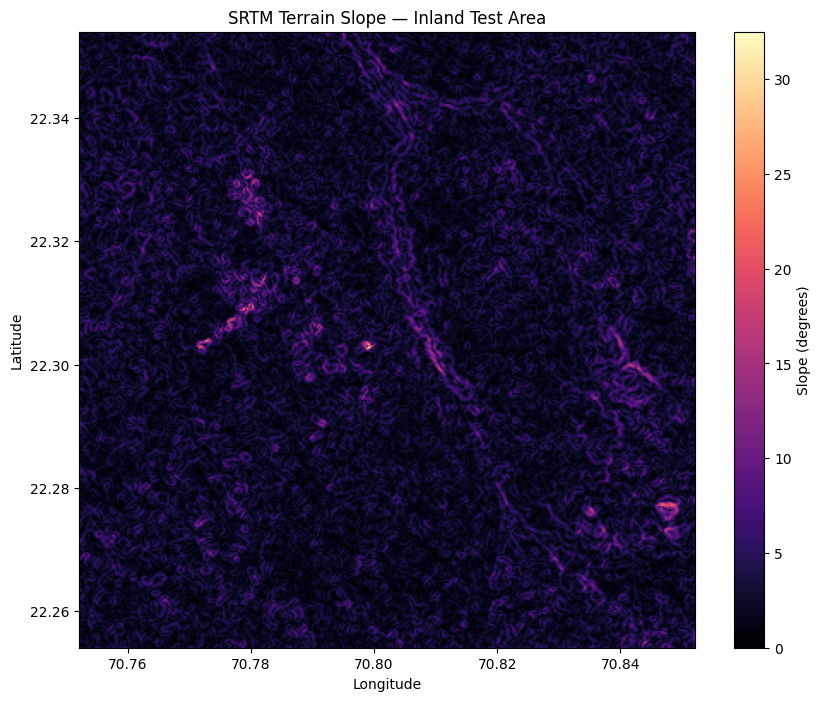

In [33]:

plt.figure(figsize=(10, 8))

plt.imshow(
    slope_deg,
    extent=[
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ],
    origin="upper",
    cmap="magma",
    vmin=0
)

plt.colorbar(label="Slope (degrees)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("SRTM Terrain Slope — Inland Test Area")

plt.show()


In [34]:

from scipy.ndimage import uniform_filter

# ============================================
# STEP 2.3 — TERRAIN VARIABILITY
# ============================================

# Use a neighbourhood approximately 500 m wide
window_size = 17
half_window = window_size // 2

# Identify valid elevation pixels
valid_mask = np.isfinite(dem_values)

# Replace invalid cells temporarily for calculation
safe_dem = np.where(valid_mask, dem_values, 0.0)
valid_float = valid_mask.astype(float)

# Local proportion of valid pixels
valid_fraction = uniform_filter(
    valid_float,
    size=window_size,
    mode="constant",
    cval=0.0
)

# Avoid division by zero
valid_fraction = np.maximum(valid_fraction, 1e-12)

# Local mean elevation
local_mean = (
    uniform_filter(
        safe_dem,
        size=window_size,
        mode="constant",
        cval=0.0
    ) / valid_fraction
)

# Local mean squared elevation
local_mean_sq = (
    uniform_filter(
        safe_dem ** 2,
        size=window_size,
        mode="constant",
        cval=0.0
    ) / valid_fraction
)

# Local elevation variance and standard deviation
local_variance = np.maximum(
    local_mean_sq - local_mean ** 2,
    0.0
)

elevation_std_500m = np.sqrt(local_variance)

# Exclude invalid cells
elevation_std_500m[~valid_mask] = np.nan

# Exclude the raster edges where the full neighbourhood
# is not available
elevation_std_500m[:half_window, :] = np.nan
elevation_std_500m[-half_window:, :] = np.nan
elevation_std_500m[:, :half_window] = np.nan
elevation_std_500m[:, -half_window:] = np.nan

print("Terrain variability calculated.")
print("Minimum:", np.nanmin(elevation_std_500m), "m")
print("Maximum:", np.nanmax(elevation_std_500m), "m")
print("Mean:", np.nanmean(elevation_std_500m), "m")


Terrain variability calculated.
Minimum: 1.0485399706356462 m
Maximum: 10.228037743054152 m
Mean: 2.57237357483133 m


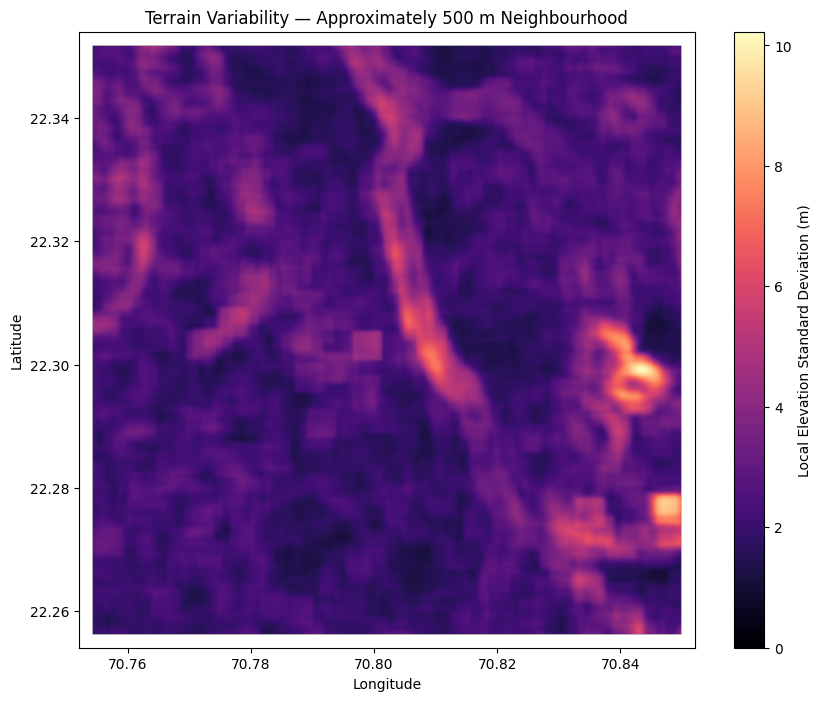

In [35]:

plt.figure(figsize=(10, 8))

plt.imshow(
    elevation_std_500m,
    extent=[
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ],
    origin="upper",
    cmap="magma",
    vmin=0
)

plt.colorbar(
    label="Local Elevation Standard Deviation (m)"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Terrain Variability — Approximately 500 m Neighbourhood")

plt.show()


In [36]:

# ============================================
# STEP 2.4 — LOAD NIWE POINTS IN THE TEST AREA
# ============================================

from pathlib import Path
import pandas as pd
import rasterio

NIWE_FILE = Path("data/raw/150m_Map_Data_A_to_G.csv")
CHUNK_SIZE = 100_000

rename_map = {
    "Longitude (E)": "longitude",
    "Latitude (N)": "latitude",
    "Wind Speed (m/s)": "wind_speed",
    "Weibull A (m/s)": "weibull_a",
    "Weibull k": "weibull_k",
    "Air Density (kg/m3)": "air_density",
    "Wind Power Density (W/sq.m)": "wind_power_density"
}

if not NIWE_FILE.exists():
    raise FileNotFoundError(
        f"NIWE CSV not found: {NIWE_FILE}. "
        "Update NIWE_FILE to your actual file location."
    )

# Read bounds from the test DEM
with rasterio.open(test_dem) as src:
    bounds = src.bounds

print("DEM bounds:", bounds)

# Read the NIWE file in chunks and retain only
# the points inside the test DEM area.
local_parts = []

for chunk in pd.read_csv(
    NIWE_FILE,
    usecols=list(rename_map.keys()),
    chunksize=CHUNK_SIZE
):
    chunk = chunk.rename(columns=rename_map)

    inside = (
        chunk["longitude"].between(
            bounds.left, bounds.right
        )
        & chunk["latitude"].between(
            bounds.bottom, bounds.top
        )
    )

    if inside.any():
        local_parts.append(
            chunk.loc[inside].copy()
        )

if local_parts:
    niwe_local = pd.concat(
        local_parts,
        ignore_index=True
    )
else:
    niwe_local = pd.DataFrame(
        columns=list(rename_map.values())
    )

print("NIWE points inside test DEM:", len(niwe_local))
display(niwe_local.head())


DEM bounds: BoundingBox(left=70.75208333333333, bottom=22.254027777777775, right=70.85208333333333, top=22.354027777777777)
NIWE points inside test DEM: 625


,longitude,latitude,wind_speed,weibull_a,weibull_k,air_density,wind_power_density
0,70.754,22.258,6.561,7.374,2.739,1.138,238.23
1,70.754,22.262,6.546,7.358,2.735,1.139,237.03
2,70.754,22.266,6.533,7.343,2.734,1.139,235.68
3,70.754,22.270,6.524,7.333,2.734,1.139,234.69
4,70.754,22.274,6.521,7.330,2.735,1.139,234.32


In [37]:

# ============================================
# STEP 2.5 — CREATE APPROX. 500 m AGGREGATES
# ============================================

from scipy.ndimage import uniform_filter

window_size = 17
half_window = window_size // 2


def neighbourhood_mean(array, window=17):
    """Calculate a local mean; require a complete valid window."""

    valid = np.isfinite(array)
    safe = np.where(valid, array, 0.0)

    local_sum = uniform_filter(
        safe,
        size=window,
        mode="constant",
        cval=0.0
    )

    valid_fraction = uniform_filter(
        valid.astype(float),
        size=window,
        mode="constant",
        cval=0.0
    )

    result = local_sum / np.maximum(valid_fraction, 1e-12)

    # Require all pixels in the neighbourhood to be valid.
    result[valid_fraction < 0.999999] = np.nan

    # Exclude edges where a complete neighbourhood is unavailable.
    h = window // 2
    result[:h, :] = np.nan
    result[-h:, :] = np.nan
    result[:, :h] = np.nan
    result[:, -h:] = np.nan

    return result


# Average elevation across the neighbourhood
elevation_mean_500m = neighbourhood_mean(
    dem_values,
    window_size
)

# Average slope across the same neighbourhood
slope_mean_500m = neighbourhood_mean(
    slope_deg,
    window_size
)

print("Elevation aggregate calculated.")
print("Slope aggregate calculated.")
print("Elevation variability raster already available.")


Elevation aggregate calculated.
Slope aggregate calculated.
Elevation variability raster already available.


In [38]:

# ============================================
# STEP 2.6 — EXTRACT TERRAIN AT NIWE LOCATIONS
# ============================================

from rasterio.transform import rowcol

# Convert geographic coordinates to raster indices
rows, cols = rowcol(
    transform,
    niwe_local["longitude"].to_numpy(),
    niwe_local["latitude"].to_numpy()
)

rows = np.asarray(rows)
cols = np.asarray(cols)

# Keep only points with enough raster area around them
# to calculate a complete 17 x 17 neighbourhood.
inside_full_window = (
    (rows >= half_window)
    & (rows < dem_values.shape[0] - half_window)
    & (cols >= half_window)
    & (cols < dem_values.shape[1] - half_window)
)

terrain_test = niwe_local.loc[
    inside_full_window
].copy()

valid_rows = rows[inside_full_window]
valid_cols = cols[inside_full_window]

# Add local terrain features
terrain_test["elevation_m"] = elevation_mean_500m[
    valid_rows, valid_cols
]

terrain_test["slope_deg"] = slope_mean_500m[
    valid_rows, valid_cols
]

terrain_test["elevation_std_500m"] = elevation_std_500m[
    valid_rows, valid_cols
]

print("Original NIWE points:", len(niwe_local))
print("Points with full terrain neighbourhood:", len(terrain_test))
print(
    "Rows with missing terrain values:",
    terrain_test[
        ["elevation_m", "slope_deg", "elevation_std_500m"]
    ].isna().any(axis=1).sum()
)

display(terrain_test.head())


Original NIWE points: 625
Points with full terrain neighbourhood: 552
Rows with missing terrain values: 0


,longitude,latitude,wind_speed,weibull_a,weibull_k,air_density,wind_power_density,elevation_m,slope_deg,elevation_std_500m
25,70.758,22.258,6.560,7.373,2.743,1.138,237.89,138.619377,2.181789,1.713100
26,70.758,22.262,6.548,7.359,2.739,1.139,237.02,135.934256,1.886642,1.964874
27,70.758,22.266,6.537,7.347,2.738,1.139,235.89,132.148789,2.625817,1.895726
28,70.758,22.270,6.531,7.340,2.739,1.139,235.18,129.584775,3.119011,2.833422
29,70.758,22.274,6.531,7.340,2.740,1.139,235.12,130.093426,2.992127,2.538614


In [39]:

terrain_columns = [
    "elevation_m",
    "slope_deg",
    "elevation_std_500m"
]

print("Test dataset shape:", terrain_test.shape)

display(
    terrain_test[terrain_columns].describe().T
)

print("\nMissing values:")
print(terrain_test[terrain_columns].isna().sum())

print("\nNegative slope values:")
print((terrain_test["slope_deg"] < 0).sum())

print("\nNegative terrain variability values:")
print((terrain_test["elevation_std_500m"] < 0).sum())


Test dataset shape: (552, 10)


,count,mean,std,min,25%,50%,75%,max
elevation_m,552.0,132.407897,10.169605,104.567474,124.493945,133.200692,140.365917,153.982699
slope_deg,552.0,2.659679,0.647517,1.522679,2.206971,2.557450,2.915040,5.539353
elevation_std_500m,552.0,2.554955,1.014638,1.095340,1.924123,2.290494,2.874096,8.396613



Missing values:
elevation_m           0
slope_deg             0
elevation_std_500m    0
dtype: int64

Negative slope values:
0

Negative terrain variability values:
0


In [40]:

# ============================================
# STEP 2.7 — SAVE TERRAIN INTEGRATION TEST
# ============================================

from pathlib import Path

TERRAIN_DIR = Path("data/terrain")
TERRAIN_DIR.mkdir(parents=True, exist_ok=True)

test_output = (
    TERRAIN_DIR / "niwe_srtm_terrain_test_rajkot.csv"
)

terrain_test.to_csv(test_output, index=False)

print("Test dataset saved successfully.")
print("Output path:", test_output)
print("Rows:", len(terrain_test))
print("Columns:", len(terrain_test.columns))

display(terrain_test.head())


Test dataset saved successfully.
Output path: data/terrain/niwe_srtm_terrain_test_rajkot.csv
Rows: 552
Columns: 10


,longitude,latitude,wind_speed,weibull_a,weibull_k,air_density,wind_power_density,elevation_m,slope_deg,elevation_std_500m
25,70.758,22.258,6.560,7.373,2.743,1.138,237.89,138.619377,2.181789,1.713100
26,70.758,22.262,6.548,7.359,2.739,1.139,237.02,135.934256,1.886642,1.964874
27,70.758,22.266,6.537,7.347,2.738,1.139,235.89,132.148789,2.625817,1.895726
28,70.758,22.270,6.531,7.340,2.739,1.139,235.18,129.584775,3.119011,2.833422
29,70.758,22.274,6.531,7.340,2.740,1.139,235.12,130.093426,2.992127,2.538614


In [41]:
from pathlib import Path

# Adjust this path if your existing drive folder structure is slightly different
DRIVE_OUTPUT = Path(
    "/content/drive/MyDrive/Projects/Wind-Energy-ML/data/terrain"
)

DRIVE_OUTPUT.mkdir(
    parents=True,
    exist_ok=True
)

terrain_test.to_csv(
    DRIVE_OUTPUT / "niwe_srtm_terrain_test_rajkot.csv",
    index=False
)

print("Saved to Google Drive.")

Saved to Google Drive.


### Redirecting Outputs to Pre-existing Google Drive Folder Structure

In [42]:
from pathlib import Path
import sys

# Configure paths using your pre-existing Drive project structure
DRIVE_PROJECT_ROOT = Path("/content/drive/MyDrive/Projects/Wind-Energy-ML")
DRIVE_TERRAIN_DIR = DRIVE_PROJECT_ROOT / "data" / "terrain"

# Check if directory exists
if DRIVE_TERRAIN_DIR.exists():
    print(f"Using existing folder: {DRIVE_TERRAIN_DIR}")
else:
    print(f"Warning: Path {DRIVE_TERRAIN_DIR} not found. Please verify your exact Drive path.")

# Resave the Rajkot terrain test dataset to your existing path
if 'terrain_test' in globals():
    test_output_drive = DRIVE_TERRAIN_DIR / "niwe_srtm_terrain_test_rajkot.csv"
    terrain_test.to_csv(test_output_drive, index=False)
    print(f"Saved Rajkot test dataset to: {test_output_drive}")
else:
    print("Warning: 'terrain_test' is not defined. Run preceding cells to define it.")

# Resave the pilot terrain dataset N22E070 to your existing path
if 'pilot_terrain' in globals():
    pilot_output_drive = DRIVE_TERRAIN_DIR / "niwe_terrain_pilot_N22E070.csv"
    pilot_terrain.to_csv(pilot_output_drive, index=False)
    print(f"Saved N22E070 pilot dataset to: {pilot_output_drive}")
else:
    print("Warning: 'pilot_terrain' is not defined. Please run the pilot extraction cells (under Phase 2.8) first.")

# Resave required SRTM tiles inventory to your existing path
if 'tile_inventory' in globals():
    inventory_output_drive = DRIVE_TERRAIN_DIR / "required_srtm_tiles.csv"
    tile_inventory.to_csv(inventory_output_drive, index=False)
    print(f"Saved SRTM tile inventory to: {inventory_output_drive}")
else:
    print("Warning: 'tile_inventory' is not defined. Please run the tile inventory cells first.")

Using existing folder: /content/drive/MyDrive/Projects/Wind-Energy-ML/data/terrain
Saved Rajkot test dataset to: /content/drive/MyDrive/Projects/Wind-Energy-ML/data/terrain/niwe_srtm_terrain_test_rajkot.csv


In [43]:

# ============================================
# PHASE 2.8 — INDIA-WIDE SRTM TILE INVENTORY
# ============================================

from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd

NIWE_FILE = Path("data/raw/150m_Map_Data_A_to_G.csv")
TERRAIN_DIR = Path("data/terrain")

TERRAIN_DIR.mkdir(parents=True, exist_ok=True)

CHUNK_SIZE = 100_000

if not NIWE_FILE.exists():
    raise FileNotFoundError(
        f"NIWE dataset not found: {NIWE_FILE}"
    )

tile_point_counts = defaultdict(int)

total_rows = 0
invalid_coordinate_rows = 0

for chunk_number, chunk in enumerate(
    pd.read_csv(
        NIWE_FILE,
        usecols=["Longitude (E)", "Latitude (N)"],
        chunksize=CHUNK_SIZE
    ),
    start=1
):
    longitude = pd.to_numeric(
        chunk["Longitude (E)"],
        errors="coerce"
    ).to_numpy()

    latitude = pd.to_numeric(
        chunk["Latitude (N)"],
        errors="coerce"
    ).to_numpy()

    total_rows += len(chunk)

    valid = (
        np.isfinite(longitude)
        & np.isfinite(latitude)
        & (longitude >= -180)
        & (longitude <= 180)
        & (latitude >= -90)
        & (latitude <= 90)
    )

    invalid_coordinate_rows += int((~valid).sum())

    if valid.any():

        # Determine the integer-degree tile containing each point
        west_degrees = np.floor(
            longitude[valid]
        ).astype(np.int16)

        south_degrees = np.floor(
            latitude[valid]
        ).astype(np.int16)

        point_tiles = pd.DataFrame({
            "west_degree": west_degrees,
            "south_degree": south_degrees
        })

        tile_counts = point_tiles.value_counts(
            sort=False
        )

        for (west, south), count in tile_counts.items():
            tile_point_counts[
                (int(west), int(south))
            ] += int(count)

    if chunk_number % 25 == 0:
        print(
            f"Processed {total_rows:,} NIWE rows"
        )

print("\nTile inventory scan completed.")
print(f"Total NIWE rows scanned: {total_rows:,}")
print(f"Invalid coordinate rows: {invalid_coordinate_rows:,}")
print(f"Unique SRTM tiles required: {len(tile_point_counts):,}")
print(
    "Points assigned to valid tiles:",
    f"{sum(tile_point_counts.values()):,}"
)


Processed 2,500,000 NIWE rows
Processed 5,000,000 NIWE rows
Processed 7,500,000 NIWE rows
Processed 10,000,000 NIWE rows
Processed 12,500,000 NIWE rows
Processed 15,000,000 NIWE rows
Processed 17,500,000 NIWE rows

Tile inventory scan completed.
Total NIWE rows scanned: 19,475,568
Invalid coordinate rows: 0
Unique SRTM tiles required: 400
Points assigned to valid tiles: 19,475,568


In [44]:

# ============================================
# CREATE SRTM TILE NAMES
# ============================================

def make_srtm_tile_name(south_degree, west_degree):
    lat_prefix = "N" if south_degree >= 0 else "S"
    lon_prefix = "E" if west_degree >= 0 else "W"

    return (
        f"{lat_prefix}{abs(south_degree):02d}"
        f"{lon_prefix}{abs(west_degree):03d}"
    )


inventory_rows = []

for (west, south), point_count in tile_point_counts.items():

    inventory_rows.append({
        "tile_name": make_srtm_tile_name(south, west),
        "west_degree": west,
        "south_degree": south,
        "left": west,
        "bottom": south,
        "right": west + 1,
        "top": south + 1,
        "niwe_point_count": point_count
    })

tile_inventory = pd.DataFrame(inventory_rows)

tile_inventory = tile_inventory.sort_values(
    ["south_degree", "west_degree"]
).reset_index(drop=True)

inventory_path = (
    TERRAIN_DIR / "required_srtm_tiles.csv"
)

tile_inventory.to_csv(
    inventory_path,
    index=False
)

print("Inventory saved:", inventory_path)
print("Unique tiles:", len(tile_inventory))
display(tile_inventory.head(20))


Inventory saved: data/terrain/required_srtm_tiles.csv
Unique tiles: 400


,tile_name,west_degree,south_degree,left,bottom,right,top,niwe_point_count
0,N06E093,93,6,93,6,94,7,11884
1,N06E094,94,6,94,6,95,7,2098
2,N07E077,77,7,77,7,78,8,620
3,N07E093,93,7,93,7,94,8,35061
4,N07E094,94,7,94,7,95,8,2016
5,N08E072,72,8,72,8,73,9,933
6,N08E073,73,8,73,8,74,9,2608
7,N08E076,76,8,76,8,77,9,18049
8,N08E077,77,8,77,8,78,9,58809
9,N08E078,78,8,78,8,79,9,13716


In [45]:

# ============================================
# INVENTORY VALIDATION
# ============================================

print("Tile count:", len(tile_inventory))

print(
    "Total points assigned:",
    f"{tile_inventory['niwe_point_count'].sum():,}"
)

print(
    "Duplicate tile names:",
    tile_inventory["tile_name"].duplicated().sum()
)

print("\nTiles containing the most NIWE points:")

display(
    tile_inventory.sort_values(
        "niwe_point_count",
        ascending=False
    ).head(10)
)

print("\nTile inventory preview:")
display(tile_inventory.head())


Tile count: 400
Total points assigned: 19,475,568
Duplicate tile names: 0

Tiles containing the most NIWE points:


,tile_name,west_degree,south_degree,left,bottom,right,top,niwe_point_count
381,N34E078,78,34,78,34,79,35,62500
380,N34E077,77,34,77,34,78,35,62500
379,N34E076,76,34,76,34,77,35,62500
378,N34E075,75,34,75,34,76,35,62500
377,N34E074,74,34,74,34,75,35,62500
374,N33E078,78,33,78,33,79,34,62500
373,N33E077,77,33,77,33,78,34,62500
372,N33E076,76,33,76,33,77,34,62500
371,N33E075,75,33,75,33,76,34,62500
370,N33E074,74,33,74,33,75,34,62500



Tile inventory preview:


,tile_name,west_degree,south_degree,left,bottom,right,top,niwe_point_count
0,N06E093,93,6,93,6,94,7,11884
1,N06E094,94,6,94,6,95,7,2098
2,N07E077,77,7,77,7,78,8,620
3,N07E093,93,7,93,7,94,8,35061
4,N07E094,94,7,94,7,95,8,2016


In [46]:
from pathlib import Path

DRIVE_TERRAIN_DIR = Path(
    "/content/drive/MyDrive/Projects/Wind-Energy-ML/data/terrain"
)

DRIVE_TERRAIN_DIR.mkdir(
    parents=True,
    exist_ok=True
)

inventory_drive_path = (
    DRIVE_TERRAIN_DIR / "required_srtm_tiles.csv"
)

tile_inventory.to_csv(
    inventory_drive_path,
    index=False
)

print("Tile inventory saved:", inventory_drive_path)
print("Total tiles:", len(tile_inventory))

Tile inventory saved: /content/drive/MyDrive/Projects/Wind-Energy-ML/data/terrain/required_srtm_tiles.csv
Total tiles: 400


In [47]:

pilot_tile_name = "N22E070"

pilot_row = tile_inventory.loc[
    tile_inventory["tile_name"] == pilot_tile_name
]

if pilot_row.empty:
    raise ValueError(
        f"{pilot_tile_name} was not found in the inventory."
    )

pilot = pilot_row.iloc[0]

west = int(pilot["west_degree"])
south = int(pilot["south_degree"])

print("Pilot tile:", pilot["tile_name"])
print("NIWE points:", int(pilot["niwe_point_count"]))
print("Bounds:", (west, south, west + 1, south + 1))


Pilot tile: N22E070
NIWE points: 61992
Bounds: (70, 22, 71, 23)


In [48]:

NIWE_FILE = Path("data/raw/150m_Map_Data_A_to_G.csv")
CHUNK_SIZE = 100_000

rename_map = {
    "Longitude (E)": "longitude",
    "Latitude (N)": "latitude",
    "Wind Speed (m/s)": "wind_speed",
    "Weibull A (m/s)": "weibull_a",
    "Weibull k": "weibull_k",
    "Air Density (kg/m3)": "air_density",
    "Wind Power Density (W/sq.m)": "wind_power_density"
}

pilot_parts = []

for chunk in pd.read_csv(
    NIWE_FILE,
    usecols=list(rename_map.keys()),
    chunksize=CHUNK_SIZE
):
    chunk = chunk.rename(columns=rename_map)

    tile_mask = (
        (chunk["longitude"] >= west)
        & (chunk["longitude"] < west + 1)
        & (chunk["latitude"] >= south)
        & (chunk["latitude"] < south + 1)
    )

    if tile_mask.any():
        pilot_parts.append(
            chunk.loc[tile_mask].copy()
        )

pilot_points = (
    pd.concat(pilot_parts, ignore_index=True)
    if pilot_parts
    else pd.DataFrame(columns=list(rename_map.values()))
)

expected_count = int(pilot["niwe_point_count"])

print("Expected point count:", expected_count)
print("Extracted point count:", len(pilot_points))
print(
    "Count matches inventory:",
    len(pilot_points) == expected_count
)

display(pilot_points.head())


Expected point count: 61992
Extracted point count: 61992
Count matches inventory: True


,longitude,latitude,wind_speed,weibull_a,weibull_k,air_density,wind_power_density
0,70.002,22.002,7.444,8.342,2.948,1.139,333.17
1,70.002,22.006,7.423,8.315,2.984,1.139,328.10
2,70.002,22.010,7.413,8.300,3.014,1.139,324.96
3,70.002,22.014,7.413,8.297,3.036,1.138,323.38
4,70.002,22.018,7.422,8.305,3.051,1.138,323.69


In [49]:

import elevation

SRTM_DIR = Path("data/srtm")
SRTM_DIR.mkdir(parents=True, exist_ok=True)

BUFFER_DEG = 0.01

pilot_dem_path = (
    SRTM_DIR / f"{pilot_tile_name}_buffered.tif"
)

dem_bounds = (
    west - BUFFER_DEG,
    south - BUFFER_DEG,
    west + 1 + BUFFER_DEG,
    south + 1 + BUFFER_DEG
)

if not pilot_dem_path.exists():
    elevation.clip(
        bounds=dem_bounds,
        output=str(pilot_dem_path)
    )

print("Pilot DEM:", pilot_dem_path)
print("DEM exists:", pilot_dem_path.exists())


Pilot DEM: data/srtm/N22E070_buffered.tif
DEM exists: True


In [50]:

# ============================================
# STEP 2.9 — INSPECT FULL PILOT DEM
# ============================================

import rasterio
import numpy as np
import matplotlib.pyplot as plt

with rasterio.open(pilot_dem_path) as src:

    pilot_dem = src.read(1, masked=True)

    pilot_transform = src.transform
    pilot_crs = src.crs
    pilot_nodata = src.nodata
    pilot_bounds = src.bounds
    pilot_resolution = src.res

    pilot_width = src.width
    pilot_height = src.height

# Convert to floating point, preserving invalid pixels
pilot_dem_values = (
    pilot_dem.astype("float64").filled(np.nan)
)

valid_pilot = pilot_dem_values[
    np.isfinite(pilot_dem_values)
]

print("CRS:", pilot_crs)
print("Raster dimensions:", pilot_width, "x", pilot_height)
print("Resolution:", pilot_resolution)
print("Bounds:", pilot_bounds)
print("NoData:", pilot_nodata)

print("\nElevation statistics:")
print("Minimum:", np.min(valid_pilot))
print("Maximum:", np.max(valid_pilot))
print("Mean:", np.mean(valid_pilot))

print(
    "Missing pixel percentage:",
    np.isnan(pilot_dem_values).mean() * 100
)


CRS: EPSG:4326
Raster dimensions: 3672 x 3672
Resolution: (0.0002777777777777778, 0.0002777777777777778)
Bounds: BoundingBox(left=69.98986111111111, bottom=21.99013888888889, right=71.0098611111111, top=23.01013888888889)
NoData: -32768.0

Elevation statistics:
Minimum: -38.0
Maximum: 268.0
Mean: 74.59915516527357
Missing pixel percentage: 0.0


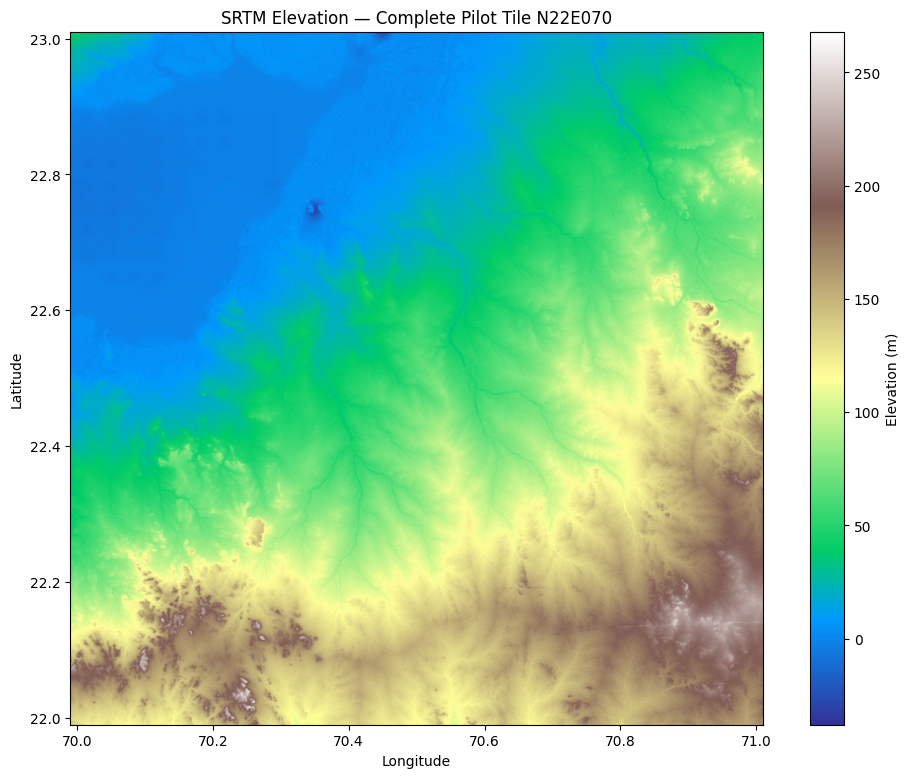

In [51]:

plt.figure(figsize=(12, 9))

plt.imshow(
    pilot_dem,
    extent=[
        pilot_bounds.left,
        pilot_bounds.right,
        pilot_bounds.bottom,
        pilot_bounds.top
    ],
    origin="upper",
    cmap="terrain"
)

plt.colorbar(label="Elevation (m)")

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.title("SRTM Elevation — Complete Pilot Tile N22E070")

plt.show()


In [52]:
pilot_transform
pilot_dem_values
pilot_bounds

BoundingBox(left=69.98986111111111, bottom=21.99013888888889, right=71.0098611111111, top=23.01013888888889)

In [53]:

# ============================================
# STEP 2.10 — PILOT TILE SLOPE CALCULATION
# ============================================

# Ensure that this test raster has no missing cells.
# Missing-data handling will be added to the
# nationwide processing function.

if not np.isfinite(pilot_dem_values).all():
    raise ValueError(
        "Pilot DEM contains invalid pixels. "
        "Handle NoData before calculating slope."
    )

height, width = pilot_dem_values.shape

# Calculate the latitude of each raster row
row_indices = np.arange(height)

row_latitudes = (
    pilot_transform.f
    + (row_indices + 0.5) * pilot_transform.e
)

# Convert angular pixel dimensions to metres
pixel_height_m = (
    110574 * abs(pilot_transform.e)
)

pixel_width_m = (
    111320
    * np.cos(np.deg2rad(row_latitudes))
    * abs(pilot_transform.a)
)

# Calculate elevation gradients
dz_drow = np.gradient(
    pilot_dem_values,
    axis=0
)

dz_dcol = np.gradient(
    pilot_dem_values,
    axis=1
)

# Convert to elevation change per metre
dz_dy = dz_drow / pixel_height_m

dz_dx = (
    dz_dcol / pixel_width_m[:, None]
)

# Calculate slope in degrees
pilot_slope_deg = np.degrees(
    np.arctan(
        np.hypot(dz_dx, dz_dy)
    )
)

print("Pilot slope calculation completed.")

print("Minimum:", np.min(pilot_slope_deg))
print("Maximum:", np.max(pilot_slope_deg))
print("Mean:", np.mean(pilot_slope_deg))


Pilot slope calculation completed.
Minimum: 0.0
Maximum: 47.092630161473735
Mean: 2.1277706303116886


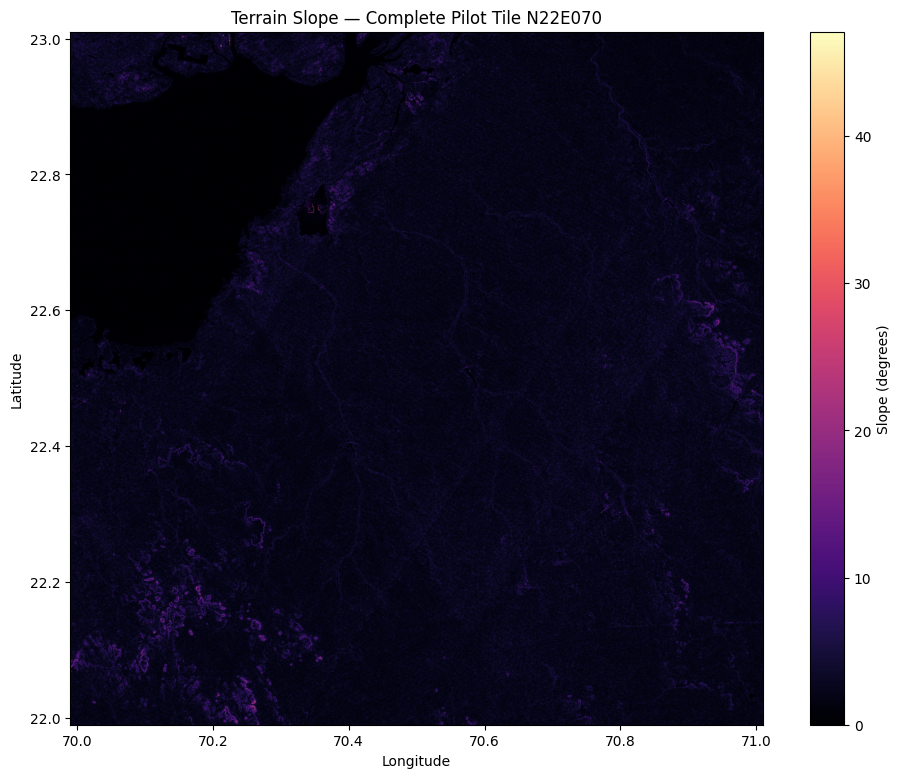

In [54]:

plt.figure(figsize=(12, 9))

plt.imshow(
    pilot_slope_deg,
    extent=[
        pilot_bounds.left,
        pilot_bounds.right,
        pilot_bounds.bottom,
        pilot_bounds.top
    ],
    origin="upper",
    cmap="magma",
    vmin=0
)

plt.colorbar(label="Slope (degrees)")

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.title("Terrain Slope — Complete Pilot Tile N22E070")

plt.show()


In [55]:

# ============================================
# STEP 2.11 — PILOT TERRAIN VARIABILITY
# ============================================

from scipy.ndimage import uniform_filter

WINDOW_SIZE = 17
HALF_WINDOW = WINDOW_SIZE // 2

# Valid elevation pixels
pilot_valid_mask = np.isfinite(pilot_dem_values)

# Prepare elevation data
safe_pilot_dem = np.where(
    pilot_valid_mask,
    pilot_dem_values,
    0.0
)

valid_float = pilot_valid_mask.astype(float)

# Calculate local valid-pixel proportion
valid_fraction = uniform_filter(
    valid_float,
    size=WINDOW_SIZE,
    mode="constant",
    cval=0.0
)

# Local elevation mean
local_mean = (
    uniform_filter(
        safe_pilot_dem,
        size=WINDOW_SIZE,
        mode="constant",
        cval=0.0
    ) / np.maximum(valid_fraction, 1e-12)
)

# Local squared elevation mean
local_mean_sq = (
    uniform_filter(
        safe_pilot_dem ** 2,
        size=WINDOW_SIZE,
        mode="constant",
        cval=0.0
    ) / np.maximum(valid_fraction, 1e-12)
)

# Local elevation standard deviation
local_variance = np.maximum(
    local_mean_sq - local_mean ** 2,
    0.0
)

pilot_elevation_std_500m = np.sqrt(
    local_variance
)

# Retain only complete valid neighbourhoods
pilot_elevation_std_500m[
    valid_fraction < 0.999999
] = np.nan

# Exclude incomplete raster edges
h = HALF_WINDOW

pilot_elevation_std_500m[:h, :] = np.nan
pilot_elevation_std_500m[-h:, :] = np.nan
pilot_elevation_std_500m[:, :h] = np.nan
pilot_elevation_std_500m[:, -h:] = np.nan

print("Pilot terrain variability calculated.")

print("Minimum:",
      np.nanmin(pilot_elevation_std_500m), "m")

print("Maximum:",
      np.nanmax(pilot_elevation_std_500m), "m")

print("Mean:",
      np.nanmean(pilot_elevation_std_500m), "m")


Pilot terrain variability calculated.
Minimum: 0.0 m
Maximum: 33.790930582320236 m
Mean: 2.0742270124361086 m


In [56]:

# ============================================
# STEP 2.12 — AGGREGATE TERRAIN SURFACES
# ============================================

pilot_elevation_mean_500m = local_mean.copy()

pilot_slope_mean_500m = neighbourhood_mean(
    pilot_slope_deg,
    WINDOW_SIZE
)

# Exclude invalid elevation neighbourhoods
pilot_elevation_mean_500m[
    valid_fraction < 0.999999
] = np.nan

# Exclude incomplete raster edges
pilot_elevation_mean_500m[:h, :] = np.nan
pilot_elevation_mean_500m[-h:, :] = np.nan
pilot_elevation_mean_500m[:, :h] = np.nan
pilot_elevation_mean_500m[:, -h:] = np.nan

print("Terrain surfaces prepared.")

print("Elevation:",
      np.nanmean(pilot_elevation_mean_500m))

print("Slope:",
      np.nanmean(pilot_slope_mean_500m))

print("Terrain variability:",
      np.nanmean(pilot_elevation_std_500m))


Terrain surfaces prepared.
Elevation: 74.55037789296115
Slope: 2.1272392317408104
Terrain variability: 2.0742270124361086


In [57]:
pilot_elevation_mean_500m
pilot_slope_mean_500m
pilot_elevation_std_500m

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(3672, 3672))

In [58]:

# ============================================
# STEP 2.13 — EXTRACT TERRAIN FEATURES
# ============================================

from rasterio.transform import rowcol

# Obtain NIWE coordinates
pilot_lons = pilot_points["longitude"].to_numpy()
pilot_lats = pilot_points["latitude"].to_numpy()

# Convert coordinates into raster row/column indices
pilot_rows, pilot_cols = rowcol(
    pilot_transform,
    pilot_lons,
    pilot_lats
)

pilot_rows = np.asarray(pilot_rows)
pilot_cols = np.asarray(pilot_cols)

# Check whether all coordinates are inside the raster
inside_raster = (
    (pilot_rows >= 0)
    & (pilot_rows < pilot_dem_values.shape[0])
    & (pilot_cols >= 0)
    & (pilot_cols < pilot_dem_values.shape[1])
)

print("Total NIWE points:", len(pilot_points))
print("Points inside DEM:", inside_raster.sum())
print("Points outside DEM:", (~inside_raster).sum())


Total NIWE points: 61992
Points inside DEM: 61992
Points outside DEM: 0


In [59]:

# ============================================
# ATTACH TERRAIN FEATURES
# ============================================

pilot_terrain = pilot_points.loc[
    inside_raster
].copy()

valid_rows = pilot_rows[inside_raster]
valid_cols = pilot_cols[inside_raster]

# Extract aggregated terrain values
pilot_terrain["elevation_m"] = (
    pilot_elevation_mean_500m[valid_rows, valid_cols]
)

pilot_terrain["slope_deg"] = (
    pilot_slope_mean_500m[valid_rows, valid_cols]
)

pilot_terrain["elevation_std_500m"] = (
    pilot_elevation_std_500m[valid_rows, valid_cols]
)

# Identify records with missing terrain values
terrain_features = [
    "elevation_m",
    "slope_deg",
    "elevation_std_500m"
]

missing_mask = pilot_terrain[
    terrain_features
].isna().any(axis=1)

print("Terrain records:", len(pilot_terrain))
print("Missing terrain records:", missing_mask.sum())
print("Valid terrain records:", (~missing_mask).sum())

display(pilot_terrain.head())


Terrain records: 61992
Missing terrain records: 0
Valid terrain records: 61992


,longitude,latitude,wind_speed,weibull_a,weibull_k,air_density,wind_power_density,elevation_m,slope_deg,elevation_std_500m
0,70.002,22.002,7.444,8.342,2.948,1.139,333.17,131.480969,2.056731,1.511370
1,70.002,22.006,7.423,8.315,2.984,1.139,328.10,134.892734,1.984958,2.096029
2,70.002,22.010,7.413,8.300,3.014,1.139,324.96,137.882353,2.467139,2.464980
3,70.002,22.014,7.413,8.297,3.036,1.138,323.38,141.792388,2.306021,2.969011
4,70.002,22.018,7.422,8.305,3.051,1.138,323.69,146.214533,2.934761,4.579441


In [60]:

pilot_terrain[terrain_features].describe().T


,count,mean,std,min,25%,50%,75%,max
elevation_m,61992.0,75.050932,60.616430,-2.455363e+01,20.245675,65.847751,127.544118,240.820069
slope_deg,61992.0,2.143502,0.995447,-8.738661e-15,1.879279,2.168238,2.517068,12.693428
elevation_std_500m,61992.0,2.089347,1.607665,0.000000e+00,1.497507,1.833675,2.316754,30.861697


In [61]:

print("Negative slope values:")
print((pilot_terrain["slope_deg"] < 0).sum())

print("\nNegative terrain variability:")
print((pilot_terrain["elevation_std_500m"] < 0).sum())

print("\nNon-finite terrain values:")
print(
    (~np.isfinite(
        pilot_terrain[terrain_features]
    )).sum()
)


Negative slope values:
1753

Negative terrain variability:
0

Non-finite terrain values:
elevation_m           0
slope_deg             0
elevation_std_500m    0
dtype: int64


In [62]:

# ============================================
# SAVE PILOT TERRAIN DATASET
# Note: the floating-point slope fix below is applied after this save;
# re-run this cell after the fix (or use notebook 03's output) for clipped slopes.
# ============================================

pilot_terrain["srtm_tile"] = "N22E070"

pilot_output = (
    DRIVE_TERRAIN_DIR
    / "niwe_terrain_pilot_N22E070.csv"
)

pilot_terrain.to_csv(
    pilot_output,
    index=False
)

print("Pilot dataset saved successfully!")
print("File:", pilot_output)
print("Shape:", pilot_terrain.shape)


Pilot dataset saved successfully!
File: /content/drive/MyDrive/Projects/Wind-Energy-ML/data/terrain/niwe_terrain_pilot_N22E070.csv
Shape: (61992, 11)


In [63]:

# ============================================
# FIX 1 — HANDLE FLOATING-POINT SLOPE VALUES
# ============================================

slope_values = pilot_terrain["slope_deg"]

tolerance = 1e-10

# Identify any genuinely negative values
significant_negative = slope_values < -tolerance

print(
    "Significantly negative slope values:",
    significant_negative.sum()
)

if significant_negative.any():
    raise ValueError(
        "Unexpected negative slope values found. "
        "Investigate before correcting."
    )

# Correct negligible floating-point negatives
pilot_terrain["slope_deg"] = (
    slope_values.clip(lower=0)
)

print(
    "Remaining negative slopes:",
    (pilot_terrain["slope_deg"] < 0).sum()
)


Significantly negative slope values: 0
Remaining negative slopes: 0


In [64]:

# ============================================
# CHECK NEGATIVE ELEVATION RECORDS
# ============================================

negative_elevation = pilot_terrain[
    pilot_terrain["elevation_m"] < 0
].copy()

print(
    "Negative elevation records:",
    len(negative_elevation)
)

print(
    "Percentage:",
    len(negative_elevation) /
    len(pilot_terrain) * 100
)

display(
    negative_elevation[
        [
            "longitude",
            "latitude",
            "elevation_m",
            "slope_deg",
            "wind_speed"
        ]
    ].head(20)
)


Negative elevation records: 5952
Percentage: 9.601238869531553


,longitude,latitude,elevation_m,slope_deg,wind_speed
149,70.002,22.598,-0.647059,0.111232,7.361
150,70.002,22.602,-1.000000,0.000000,7.373
151,70.002,22.606,-1.432526,0.181884,7.383
152,70.002,22.610,-1.107266,0.086324,7.391
153,70.002,22.614,-1.000000,0.000000,7.398
154,70.002,22.618,-1.000000,0.000000,7.403
155,70.002,22.622,-1.000000,0.000000,7.409
156,70.002,22.626,-1.000000,0.000000,7.413
157,70.002,22.630,-1.000000,0.000000,7.418
158,70.002,22.634,-1.000000,0.000000,7.423


In [65]:
for name, array in {
    "Elevation": pilot_elevation_mean_500m,
    "Slope": pilot_slope_mean_500m,
    "Terrain variability": pilot_elevation_std_500m
}.items():

    print(
        name,
        "Valid pixels:",
        np.isfinite(array).sum(),
        "/",
        array.size
    )

Elevation Valid pixels: 13366336 / 13483584
Slope Valid pixels: 13366336 / 13483584
Terrain variability Valid pixels: 13366336 / 13483584


In [66]:

# ============================================
# INVESTIGATE NEGATIVE ELEVATION LOCATIONS
# ============================================

negative_elevation = pilot_terrain[
    pilot_terrain["elevation_m"] < 0
].copy()

print("Negative elevation records:", len(negative_elevation))

print(
    "Percentage:",
    round(
        len(negative_elevation) /
        len(pilot_terrain) * 100,
        3
    )
)

print("\nLongitude range:")
print(
    negative_elevation["longitude"].min(),
    negative_elevation["longitude"].max()
)

print("\nLatitude range:")
print(
    negative_elevation["latitude"].min(),
    negative_elevation["latitude"].max()
)


Negative elevation records: 5952
Percentage: 9.601

Longitude range:
70.002 70.458

Latitude range:
22.554 22.998


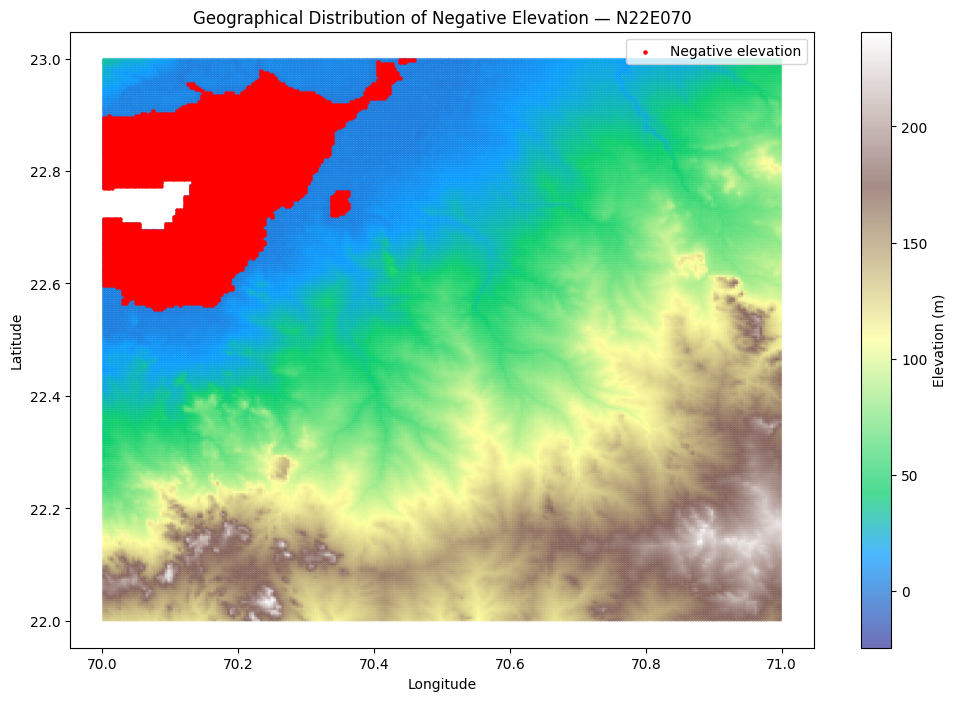

In [67]:

# ============================================
# SPATIAL DISTRIBUTION OF NEGATIVE ELEVATIONS
# ============================================

plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    pilot_terrain["longitude"],
    pilot_terrain["latitude"],
    c=pilot_terrain["elevation_m"],
    cmap="terrain",
    s=3,
    alpha=0.7
)

plt.scatter(
    negative_elevation["longitude"],
    negative_elevation["latitude"],
    color="red",
    s=5,
    label="Negative elevation"
)

plt.colorbar(
    scatter,
    label="Elevation (m)"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.title(
    "Geographical Distribution of Negative Elevation — N22E070"
)

plt.legend()
plt.show()


In [68]:

# ============================================
# NEGATIVE ELEVATION VALUE DISTRIBUTION
# ============================================

display(
    negative_elevation["elevation_m"]
    .round(2)
    .value_counts()
    .head(20)
    .rename_axis("Elevation (m)")
    .reset_index(name="Frequency")
)


,Elevation (m),Frequency
0,-2.00,1146
1,-3.00,1014
2,-1.00,731
3,-4.00,452
4,-5.00,290
5,-6.00,269
6,-7.00,36
7,-1.01,23
8,-1.99,21
9,-3.02,15


In [69]:

import requests
from pathlib import Path

WORLDCOVER_DIR = Path("data/worldcover")
WORLDCOVER_DIR.mkdir(parents=True, exist_ok=True)

worldcover_file = (
    WORLDCOVER_DIR /
    "ESA_WorldCover_2021_N21E069.tif"
)

url = (
    "https://esa-worldcover.s3.eu-central-1.amazonaws.com/"
    "v200/2021/map/"
    "ESA_WorldCover_10m_2021_v200_N21E069_Map.tif"
)

if not worldcover_file.exists():

    response = requests.get(
        url,
        stream=True,
        timeout=180
    )

    response.raise_for_status()

    with open(worldcover_file, "wb") as f:
        for block in response.iter_content(1024 * 1024):
            if block:
                f.write(block)

print("WorldCover downloaded:", worldcover_file.exists())
print("File size (MB):",
      round(worldcover_file.stat().st_size / (1024**2), 2))


WorldCover downloaded: True
File size (MB): 88.63


In [70]:

import rasterio

with rasterio.open(worldcover_file) as src:

    print("CRS:", src.crs)
    print("Dimensions:", src.width, src.height)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("NoData:", src.nodata)


CRS: EPSG:4326
Dimensions: 36000 36000
Resolution: (8.333333333333333e-05, 8.333333333333333e-05)
Bounds: BoundingBox(left=69.0, bottom=21.0, right=72.0, top=24.0)
NoData: 0.0


In [71]:

with rasterio.open(worldcover_file) as src:

    if src.crs != pilot_crs:
        raise ValueError(
            "WorldCover and NIWE coordinates "
            "need coordinate transformation."
        )

    worldcover_values = np.array([
        value[0]
        for value in src.sample(
            zip(
                pilot_terrain["longitude"],
                pilot_terrain["latitude"]
            )
        )
    ])

pilot_terrain["worldcover_class"] = worldcover_values

class_names = {
    10: "Tree cover",
    20: "Shrubland",
    30: "Grassland",
    40: "Cropland",
    50: "Built-up",
    60: "Bare/sparse vegetation",
    70: "Snow and ice",
    80: "Permanent water",
    90: "Herbaceous wetland",
    95: "Mangroves",
    100: "Moss and lichen",
    0: "NoData"
}

pilot_terrain["land_cover"] = (
    pilot_terrain["worldcover_class"]
    .map(class_names)
    .fillna("Unknown")
)

display(
    pilot_terrain["land_cover"]
    .value_counts()
    .rename_axis("Land Cover")
    .reset_index(name="Point Count")
)


,Land Cover,Point Count
0,Cropland,38272
1,Permanent water,9289
2,Shrubland,8159
3,Bare/sparse vegetation,2267
4,Built-up,1839
5,Tree cover,814
6,Grassland,810
7,Mangroves,527
8,Herbaceous wetland,15


In [72]:

# ============================================
# COMPARE ELEVATION WITH LAND COVER
# ============================================

pilot_terrain["negative_elevation"] = (
    pilot_terrain["elevation_m"] < 0
)

comparison = pd.crosstab(
    pilot_terrain["land_cover"],
    pilot_terrain["negative_elevation"],
    margins=True
)

comparison.columns = [
    "Non-negative elevation",
    "Negative elevation",
    "Total"
]

display(comparison)

print("\nLand-cover distribution among negative elevations:")

display(
    pilot_terrain.loc[
        pilot_terrain["negative_elevation"],
        "land_cover"
    ].value_counts()
)


,Non-negative elevation,Negative elevation,Total
land_cover,,,
Bare/sparse vegetation,2266,1,2267
Built-up,1839,0,1839
Cropland,38272,0,38272
Grassland,810,0,810
Herbaceous wetland,14,1,15
Mangroves,527,0,527
Permanent water,3339,5950,9289
Shrubland,8159,0,8159
Tree cover,814,0,814



Land-cover distribution among negative elevations:


,count
land_cover,
Permanent water,5950
Bare/sparse vegetation,1
Herbaceous wetland,1


In [73]:

from pyproj import Transformer
from shapely.geometry import box, mapping
from shapely.ops import transform as transform_geometry
from rasterio.mask import mask

# Gujarat pilot tile: UTM Zone 42N
to_utm = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32642",
    always_xy=True
)

to_geo = Transformer.from_crs(
    "EPSG:32642",
    "EPSG:4326",
    always_xy=True
)

print("Coordinate transformations prepared.")


Coordinate transformations prepared.


In [74]:

# ============================================
# STRATIFIED LAND-COVER TEST SAMPLE
# ============================================

sample_parts = []

for class_code, group in pilot_terrain.groupby(
    "worldcover_class"
):

    part = group.sample(
        n=min(50, len(group)),
        random_state=42
    )

    sample_parts.append(part)

landcover_test_sample = pd.concat(
    sample_parts,
    ignore_index=True
)

print(
    "Diagnostic sample size:",
    len(landcover_test_sample)
)

display(
    landcover_test_sample["land_cover"]
    .value_counts()
)


Diagnostic sample size: 415


,count
land_cover,
Tree cover,50
Shrubland,50
Grassland,50
Cropland,50
Built-up,50
Bare/sparse vegetation,50
Permanent water,50
Mangroves,50
Herbaceous wetland,15


### 500 m neighbourhood land cover (diagnostic sample)

*Code corrected after review: the column rename was inside the loop (it only worked because of an earlier kernel state) and `non_water_pct` was never computed. Outputs were cleared — re-run to regenerate. For all points, notebook 03 computes land-cover percentages per NIWE cell.*

In [75]:

# ============================================
# 500 M NEIGHBOURHOOD LAND-COVER ANALYSIS
# ============================================

class_codes = {
    "cropland_pct": 40,
    "builtup_pct": 50,
    "water_pct": 80,
    "wetland_pct": 90,
    "mangrove_pct": 95
}

records = []

with rasterio.open(worldcover_file) as src:

    for idx, row in landcover_test_sample.iterrows():

        # Convert NIWE coordinate to metres
        x, y = to_utm.transform(
            row["longitude"],
            row["latitude"]
        )

        # Create a 500 m x 500 m square
        polygon_utm = box(
            x - 250,
            y - 250,
            x + 250,
            y + 250
        )

        # Convert the polygon to raster CRS
        polygon_geo = transform_geometry(
            to_geo.transform,
            polygon_utm
        )

        try:

            clipped, _ = mask(
                src,
                [mapping(polygon_geo)],
                crop=True,
                filled=False
            )

            values = clipped[0].compressed()

            # Remove NoData
            values = values[values != 0]

            if len(values) == 0:
                continue

            result = {
                "longitude": row["longitude"],
                "latitude": row["latitude"],
                "original_land_cover": row["land_cover"]
            }

            for feature, code in class_codes.items():

                result[feature] = (
                    np.sum(values == code)
                    / len(values) * 100
                )

            result["non_water_pct"] = 100 - result["water_pct"]

            records.append(result)

        except ValueError:
            continue

landcover_neighbourhood = pd.DataFrame(records)

print(
    "Successfully processed:",
    len(landcover_neighbourhood)
)

display(landcover_neighbourhood.head())


/tmp/ipykernel_1007/3207051374.py:34: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  polygon_geo = transform_geometry(
/tmp/ipykernel_1007/3207051374.py:34: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  polygon_geo = transform_geometry(
/tmp/ipykernel_1007/3207051374.py:34: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  polygon_geo = transform_geometry(
/tmp/ipykernel_1007/3207051374.py:34: DeprecationWarning: 

Successfully processed: 415


/tmp/ipykernel_1007/3207051374.py:34: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  polygon_geo = transform_geometry(
/tmp/ipykernel_1007/3207051374.py:34: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  polygon_geo = transform_geometry(
/tmp/ipykernel_1007/3207051374.py:34: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  polygon_geo = transform_geometry(
/tmp/ipykernel_1007/3207051374.py:34: DeprecationWarning: 

,longitude,latitude,original_land_cover,cropland_pct,builtup_pct,water_pct,wetland_pct,mangrove_pct,non_water_pct
0,70.350,22.534,Tree cover,52.745849,0.000000,0.000000,0.0,0.0,100.000000
1,70.814,22.298,Tree cover,14.431673,68.135377,0.095785,0.0,0.0,99.904215
2,70.314,22.690,Tree cover,90.006386,1.085568,0.000000,0.0,0.0,100.000000
3,70.406,22.738,Tree cover,3.256705,0.000000,0.159642,0.0,0.0,99.840358
4,70.778,22.018,Tree cover,98.946360,0.031928,0.000000,0.0,0.0,100.000000


In [76]:

landcover_features = [
    "water_pct",
    "cropland_pct",
    "builtup_pct",
    "wetland_pct",
    "mangrove_pct",
    "non_water_pct"
]

display(
    landcover_neighbourhood[
        landcover_features
    ].describe().T
)

print("\nAverage neighbourhood water percentage:")
print(
    landcover_neighbourhood["water_pct"].mean()
)

print("\nAverage neighbourhood non-water percentage:")
print(
    landcover_neighbourhood["non_water_pct"].mean()
)


,count,mean,std,min,25%,50%,75%,max
water_pct,415.0,15.816445,31.254084,0.0,0.000000,0.000000,10.951469,100.000000
cropland_pct,415.0,33.369125,33.982072,0.0,1.069604,23.450906,59.083653,100.000000
builtup_pct,415.0,10.257477,22.203929,0.0,0.000000,0.000000,5.452530,100.000000
wetland_pct,415.0,0.792820,4.536261,0.0,0.000000,0.000000,0.000000,40.644955
mangrove_pct,415.0,9.480511,25.747075,0.0,0.000000,0.000000,0.000000,100.000000
non_water_pct,415.0,84.183555,31.254084,0.0,89.048531,100.000000,100.000000,100.000000



Average neighbourhood water percentage:
15.816445295562563

Average neighbourhood non-water percentage:
84.18355470443743
